In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import pandas as pd

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

In [2]:
from src.workflows.search_workflow import SearchWorkflow, SearchState
from src.lib.knowledge import Knowledge
from src.models.workflow import WorkflowSettings


In [3]:
df = pd.read_csv("../data/transactions.csv", index_col="transaction_id", parse_dates=["transaction_date"])
df.head()

,transaction_date,transaction_type,category,amount_ngn,payment_channel,description,suspicious_flag
transaction_id,,,,,,,
TXN0001,2026-04-13,Expense,Utilities,24563.25,POS,Utilities transaction,0
TXN0002,2026-09-28,Expense,Bank Charges,11339.64,Direct Debit,Bank Charges transaction,0
TXN0003,2026-04-17,Income,Sales,16232.84,Bank Transfer,Sales transaction,0
TXN0004,2026-03-13,Expense,Utilities,3152.87,Direct Debit,Utilities transaction,0
TXN0005,2026-07-08,Income,Sales,18004.45,Cash,Sales transaction,1


In [4]:
km = Knowledge("testing")
await km.ingest_from_dataframe(df, "testing")

[2026-10-22 14:35:29] [INFO] [Knowledge] - [Deleted document with id testing from vector store]
[2026-10-22 14:35:32] [INFO] [Knowledge] - [Ingested dataframe with id testing into vector store]


In [5]:
workflow = SearchWorkflow(['testing'], settings=WorkflowSettings(online=False))

In [6]:
workflow.invoke(SearchState(query="Category"))

[2026-10-22 14:35:33] [INFO] [SearchWorkflow] - [Invoked]
[2026-10-22 14:35:33] [INFO] [Knowledge] - [Looking for documents]
[2026-10-22 14:35:36] [INFO] [SearchWorkflow] - [Retrieved Documents]


[Document(id='testing_25', metadata={'file_id': 'testing'}, page_content='transaction_date:2026-05-14 00:00:00 | transaction_type:Expense | category:Marketing | amount_ngn:6959.8 | payment_channel:Bank Transfer | description:Marketing transaction | suspicious_flag:0\ntransaction_date:2026-01-28 00:00:00 | transaction_type:Income | category:Sales | amount_ngn:88001.09 | payment_channel:Cash | description:Sales transaction | suspicious_flag:0\ntransaction_date:2026-04-18 00:00:00 | transaction_type:Income | category:Other Income | amount_ngn:14187.11 | payment_channel:POS | description:Other Income transaction | suspicious_flag:0\ntransaction_date:2026-02-13 00:00:00 | transaction_type:Income | category:Service Revenue | amount_ngn:92328.07 | payment_channel:Bank Transfer | description:Service Revenue transaction | suspicious_flag:0\ntransaction_date:2026-05-08 00:00:00 | transaction_type:Expense | category:Inventory | amount_ngn:6051.39 | payment_channel:Cash | description:Inventory tra

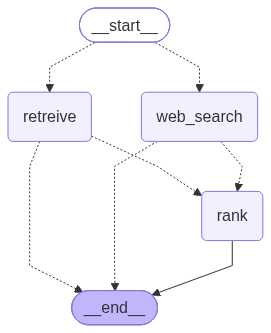

In [7]:
workflow.graph